# 📊 00 · 描述性统计与数据可视化（入门第一课）

> 统计学入门第一站：**怎么把一堆数字讲清楚**。不管是面试还是工作，
> 你拿到一组数据后的第一反应都应是——先描述它：集中趋势、离散程度、分布形状。
>
> 本节目标：手写均值/中位数/方差/分位数，与 numpy 对照；用直方图/箱线图看分布；
> 理解"平均工资被平均"这类经典陷阱（均值 vs 中位数 vs 众数）。

## 📋 本节要解决的问题

- 一组数据的"中心"到底怎么量？均值、中位数、众数各有什么适用场景？
- "离散程度"怎么量？方差/标准差/极差/IQR 各自表达什么？
- 离群值如何影响统计量？为什么看数据要先画图？
- 偏度/峰度能告诉我们什么？

## 📖 论文配图：Anscombe 四重奏：相同统计量、完全不同的数据

> **图源**：Ott VL et al. (2025) *Informative data visualization with raincloud plots in JASP*, Behavior Research Methods （开放获取，CC-BY 4.0）图 1；原图思想源自 Anscombe (1973) *Graphs in statistical analysis*, The American Statistician。

![Anscombe 四重奏：相同统计量、完全不同的数据](../figures/anscombe_quartet.jpg)

> **怎么读这张图**：四组数据 (x,y) 的均值、方差、相关系数几乎相同，但散点图形态完全不同：左上呈明显线性关系，其余三组分别是曲线、单离群点支配、竖直线。它说明**统计量必须配合图形解读**——本节的均值/方差/相关系数手算都应有散点图做"眼见为实"。


## 1️⃣ 手写集中趋势：均值 / 中位数 / 众数

**均值**（mean）对每个观测一视同仁，但对离群值敏感；
**中位数**（median）只看位置，对离群值稳健；
**众数**（mode）是出现次数最多的值，适合类别/离散数据。

面试高频问：「为什么平均数会被工资拉高？」——因为少数极高值把均值抬高，中位数不受影响。

In [1]:
import numpy as np

def my_mean(x):
    return sum(x) / len(x)

def my_median(x):
    xs = sorted(x)
    n = len(xs)
    if n % 2 == 1:
        return xs[n // 2]
    return (xs[n // 2 - 1] + xs[n // 2]) / 2

def my_mode(x):
    from collections import Counter
    c = Counter(x)
    m = max(c.values())
    return [k for k, v in c.items() if v == m]

# 测试：10 个普通值 + 1 个离群值
data = [3, 5, 7, 8, 9, 10, 11, 12, 13, 15, 500]
print('手写均值:', round(my_mean(data), 3), ' numpy:', round(np.mean(data), 3))
print('手写中位数:', my_median(data), ' numpy:', np.median(data))
print('均值 (%.1f) >> 中位数 (%.1f)，说明存在右偏离群值' % (my_mean(data), my_median(data)))

x2 = [1, 2, 2, 3, 3, 3, 4, 4, 5]
print('手写众数:', my_mode(x2), '统计学意义：数据集中在 3 附近')

# 断言：与 numpy 对照
assert abs(my_mean(data) - np.mean(data)) < 1e-9
assert my_median(data) == np.median(data)
print('\n✅ 均值/中位数与 numpy 一致')

手写均值: 53.909  numpy: 53.909
手写中位数: 10  numpy: 10.0
均值 (53.9) >> 中位数 (10.0)，说明存在右偏离群值
手写众数: [3] 统计学意义：数据集中在 3 附近

✅ 均值/中位数与 numpy 一致


## 2️⃣ 手写离散程度：方差 / 标准差 / 极差 / IQR

- **方差** var：离均差的平方平均，量纲是原数据的平方
- **标准差** std = √var：回到原量纲，便于解释
- **极差** range：max - min，只看两端，极易受离群值影响
- **IQR** = Q3 - Q1：四分位距，稳健地刻画中间 50% 数据的宽度

**面试问**：为什么用标准差而不用方差？→ 量纲一致，直接可解释。

In [2]:
def my_var(x, ddof=0):
    # ddof=0 总体方差；ddof=1 样本方差（无偏）
    n = len(x)
    mu = sum(x) / n
    return sum((v - mu) ** 2 for v in x) / (n - ddof)

def my_std(x, ddof=0):
    return my_var(x, ddof) ** 0.5

def my_quantile(x, q):
    # 线性插值分位数（与 numpy 默认一致）
    xs = sorted(x)
    n = len(xs)
    pos = (n - 1) * q
    lo = int(pos)
    hi = min(lo + 1, n - 1)
    frac = pos - lo
    return xs[lo] * (1 - frac) + xs[hi] * frac

def my_iqr(x):
    return my_quantile(x, 0.75) - my_quantile(x, 0.25)

data = [3, 5, 7, 8, 9, 10, 11, 12, 13, 15]
print('手写方差(总体):', round(my_var(data), 4), ' numpy:', round(np.var(data), 4))
print('手写方差(样本):', round(my_var(data, 1), 4), ' numpy:', round(np.var(data, ddof=1), 4))
print('手写标准差:', round(my_std(data), 4), ' numpy:', round(np.std(data), 4))
print('手写 Q1/Q3/IQR:', my_quantile(data, .25), my_quantile(data, .75), my_iqr(data))

assert abs(my_var(data) - np.var(data)) < 1e-9
assert abs(my_quantile(data, .25) - np.quantile(data, .25)) < 1e-9
print('✅ 方差/分位数与 numpy 一致')

手写方差(总体): 12.21  numpy: 12.21
手写方差(样本): 13.5667  numpy: 13.5667
手写标准差: 3.4943  numpy: 3.4943
手写 Q1/Q3/IQR: 7.25 11.75 4.5
✅ 方差/分位数与 numpy 一致


## 3️⃣ 分布形状：偏度（Skewness）与峰度（Kurtosis）

- **偏度**：分布的不对称程度。>0 右偏（长尾在右），<0 左偏（长尾在左）
- **峰度**：分布的"尖"或"厚尾"。正态分布峰度 = 3（或用 excess kurtosis = 0）

**面试问**：右偏数据用均值还是中位数？→ 常用中位数，因为均值被长尾拉向右侧。

In [3]:
def my_skewness(x):
    n = len(x); mu = np.mean(x)
    m3 = np.mean((x - mu) ** 3)
    m2 = np.mean((x - mu) ** 2) ** 1.5
    return m3 / m2

def my_excess_kurtosis(x):
    n = len(x); mu = np.mean(x)
    m4 = np.mean((x - mu) ** 4)
    m2 = np.mean((x - mu) ** 2) ** 2
    return m4 / m2 - 3

rng = np.random.RandomState(42)
# 右偏：指数分布
skew_data = rng.exponential(scale=2, size=2000)
# 正态
norm_data = rng.normal(0, 1, 2000)
from scipy import stats as _st
print('指数分布 偏度(手写):', round(my_skewness(skew_data), 3), ' scipy:', round(_st.skew(skew_data), 3))
print('指数分布 峰度(手写):', round(my_excess_kurtosis(skew_data), 3), ' scipy:', round(_st.kurtosis(skew_data), 3))
print('正态分布 偏度(手写):', round(my_skewness(norm_data), 3), ' 约 0 ✅')
print('正态分布 峰度(手写):', round(my_excess_kurtosis(norm_data), 3), ' 约 0 ✅')

指数分布 偏度(手写): 1.944  scipy: 1.944
指数分布 峰度(手写): 5.298  scipy: 5.298
正态分布 偏度(手写): -0.007  约 0 ✅
正态分布 峰度(手写): 0.029  约 0 ✅


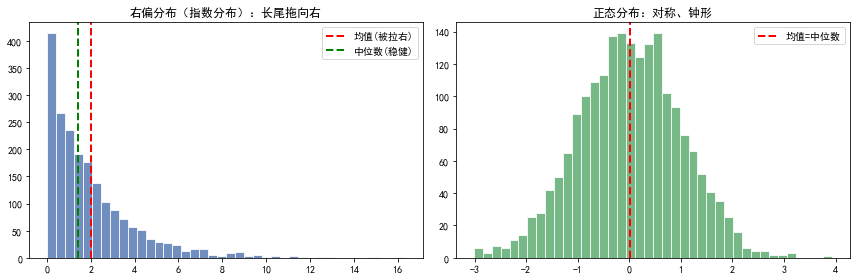

画图完成：左图展示右偏分布中均值>中位数，右图展示对称分布均值≈中位数


In [4]:
import matplotlib.pyplot as plt
# 中文显示
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(skew_data, bins=40, color='#4C72B0', alpha=.8, edgecolor='white')
axes[0].set_title('右偏分布（指数分布）：长尾拖向右', fontsize=12)
axes[0].axvline(np.mean(skew_data), color='red', ls='--', lw=2, label='均值(被拉右)')
axes[0].axvline(np.median(skew_data), color='green', ls='--', lw=2, label='中位数(稳健)')
axes[0].legend()

axes[1].hist(norm_data, bins=40, color='#55A868', alpha=.8, edgecolor='white')
axes[1].set_title('正态分布：对称、钟形', fontsize=12)
axes[1].axvline(np.mean(norm_data), color='red', ls='--', lw=2, label='均值=中位数')
axes[1].legend()
plt.tight_layout()
plt.show()
print('画图完成：左图展示右偏分布中均值>中位数，右图展示对称分布均值≈中位数')

## 4️⃣ 箱线图与离群值（IQR 判据）

箱线图（boxplot）用五个数概括分布：最小值、Q1、中位数、Q3、最大值，
并用 **1.5×IQR** 作为离群值判据：超出 [Q1−1.5·IQR, Q3+1.5·IQR] 的点标为离群值。

**面试手撕**：给你一组数据，问哪些点是离群值 → 算 Q1/Q3/IQR，套 1.5×IQR 公式。

1.5×IQR 判据识别到的离群值: [(45, '范围[-3.0,17.0]'), (-8, '范围[-3.0,17.0]')]
✅ 离群值检测正确


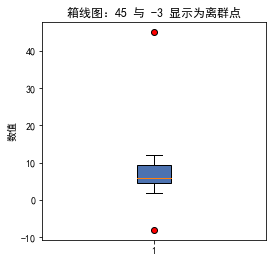

箱线图绘制完成


In [5]:
def detect_outliers_iqr(x):
    q1 = my_quantile(x, .25)
    q3 = my_quantile(x, .75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return [(v, lo, hi) for v in x if v < lo or v > hi]

data = [2, 3, 4, 5, 5, 6, 6, 7, 8, 9, 10, 11, 12, 45, -8]
outs = detect_outliers_iqr(data)
print('1.5×IQR 判据识别到的离群值:', [(v, f'范围[{lo:.1f},{hi:.1f}]') for v, lo, hi in outs])
assert len(outs) == 2, '应识别 45 和 -8 两个离群值'
print('✅ 离群值检测正确')

import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(data, vert=True, patch_artist=True,
           boxprops=dict(facecolor='#4C72B0'), flierprops=dict(marker='o', markerfacecolor='red'))
ax.set_title('箱线图：45 与 -3 显示为离群点')
ax.set_ylabel('数值')
plt.show()
print('箱线图绘制完成')

## 5️⃣ 集中趋势陷阱：均值 / 中位数 / 众数对比（面试必考）

经典的「平均工资」题：
> 老板说"我们平均工资 2 万"，为什么员工感觉只有 8 千？——因为 CEO 年薪数百万把均值拉爆了。

此时应报告 **中位数** 和 **分布形态**，而不是单一均值。

In [6]:
salaries = np.array([6000]*45 + [8000]*30 + [12000]*15 + [30000]*8 + [800000]*2)
print('45 人拿 6000、30 人拿 8000、15 人拿 12000、8 人拿 30000、2 人拿 80万')
print('均值: %.0f  中位数: %.0f  75分位: %.0f' % (salaries.mean(), np.median(salaries), np.quantile(salaries, .75)))
print()
print('→ 均值(%.0f)被 2 个高薪拉高；中位数(%.0f)更能代表"普通员工"的水平' % (salaries.mean(), np.median(salaries)))
assert salaries.mean() > np.median(salaries) * 1.5
print('✅ 均值 >> 中位数：右偏分布的典型表现')

45 人拿 6000、30 人拿 8000、15 人拿 12000、8 人拿 30000、2 人拿 80万
均值: 25300  中位数: 8000  75分位: 9000

→ 均值(25300)被 2 个高薪拉高；中位数(8000)更能代表"普通员工"的水平
✅ 均值 >> 中位数：右偏分布的典型表现


## 6️⃣ 直方图与密度：理解分布的形状

直方图的 bin 宽度影响观感：bin 太宽会抹平细节，bin 太窄会噪声很大。
KDE（核密度估计）是平滑版的直方图，适合叠加对比。

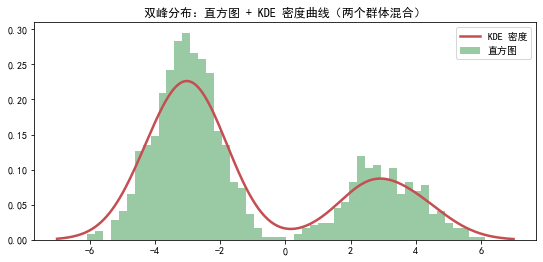

双峰分布绘制完成——两群数据混合时均值可能落在中间空洞处，务必先画图！


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
rng = np.random.RandomState(7)
x = np.concatenate([rng.normal(-3, 1, 700), rng.normal(3, 1.2, 300)])

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(x, bins=50, density=True, alpha=.6, color='#55A868', label='直方图')
xs = np.linspace(-7, 7, 300)
ax.plot(xs, stats.gaussian_kde(x)(xs), color='#C44E52', lw=2.5, label='KDE 密度')
ax.set_title('双峰分布：直方图 + KDE 密度曲线（两个群体混合）')
ax.legend()
plt.show()
print('双峰分布绘制完成——两群数据混合时均值可能落在中间空洞处，务必先画图！')

## 7️⃣ 数据标准化的两个公式（面试高频）

**z-score**：$z = \frac{x - \mu}{\sigma}$，把数据变成均值为 0、标准差为 1。
**min-max 归一化**：$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$，映射到 [0,1]。

In [8]:
def zscore(x):
    mu, sd = np.mean(x), np.std(x)
    return (x - mu) / sd

def minmax(x):
    return (x - x.min()) / (x.max() - x.min())

x = np.array([10, 20, 30, 40, 50])
z = zscore(x)
m = minmax(x)
print('原始:', x)
print('z-score:', np.round(z, 4), '→ 均值=%.2f 标准差=%.2f' % (z.mean(), z.std()))
print('min-max:', np.round(m, 4), '→ 范围[%.1f, %.1f]' % (m.min(), m.max()))
assert abs(z.mean()) < 1e-9 and abs(z.std() - 1) < 1e-9
assert abs(m.min()) < 1e-9 and abs(m.max() - 1) < 1e-9
print('✅ 两种标准化都正确')

原始: [10 20 30 40 50]
z-score: [-1.4142 -0.7071  0.      0.7071  1.4142] → 均值=0.00 标准差=1.00
min-max: [0.   0.25 0.5  0.75 1.  ] → 范围[0.0, 1.0]
✅ 两种标准化都正确


## 🧮 手算示例：五数概要与 z-score（逐步手算）

> **数据**：$x = [2, 4, 6, 8, 10]$，共 5 个观测。

**第 1 步 · 均值**：$\bar x = \frac{2+4+6+8+10}{5} = \frac{30}{5} = 6$

**第 2 步 · 总体方差**（ddof=0）：
$$\sigma^2 = \frac{(2-6)^2+(4-6)^2+(6-6)^2+(8-6)^2+(10-6)^2}{5}
= \frac{16+4+0+4+16}{5} = 8$$

**第 3 步 · 标准差**：$\sigma = \sqrt{8} \approx 2.828$

**第 4 步 · 中位数与 IQR**：排序后 [2,4,6,8,10]，中位=6；
分位插值位置 (5−1)×0.25=1 → Q1=第 2 个值 4；(5−1)×0.75=3 → Q3=第 4 个值 8；
IQR = 8−4 = 4

**第 5 步 · z-score of 10**：$z = \frac{10-6}{\sqrt{8}} = \frac{4}{2.828} \approx 1.414$

In [9]:
# 用代码验证上面的手算
import numpy as np
x = np.array([2, 4, 6, 8, 10])
print('均值(手算=6):', x.mean())
print('方差(手算=8):', x.var(ddof=0))
print('标准差(手算≈2.828):', round(x.std(ddof=0), 3))
print('中位数(手算=6):', np.median(x))
print('IQR(手算=4):', np.quantile(x, .75) - np.quantile(x, .25))
print('z-score of 10 (手算≈1.414):', round((10 - x.mean()) / x.std(ddof=0), 3))
assert abs(x.mean() - 6) < 1e-9 and abs(x.var(ddof=0) - 8) < 1e-9
assert abs(np.quantile(x,.75)-np.quantile(x,.25) - 4) < 1e-9
assert abs((10-x.mean())/x.std(ddof=0) - 4/np.sqrt(8)) < 1e-9
print('✅ 手算与代码完全一致')

均值(手算=6): 6.0
方差(手算=8): 8.0
标准差(手算≈2.828): 2.828
中位数(手算=6): 6.0
IQR(手算=4): 4.0
z-score of 10 (手算≈1.414): 1.414
✅ 手算与代码完全一致


## ✅ 自测清单

- [ ] 能手写均值/中位数/众数并说清离群值对三者的影响
- [ ] 能手写方差/标准差/IQR 并解释"为什么用标准差"
- [ ] 能解释偏度/峰度的含义，并区分均值的陷阱
- [ ] 能用 1.5×IQR 判据识别离群值
- [ ] 能解释"平均工资"式陷阱：均值 vs 中位数
- [ ] 能说明直方图 bin 宽度的影响与 KDE 的作用
- [ ] 能写出 z-score 与 min-max 公式并手算

> **面试模板一句话**：「拿到数据我先画图 + 算五数概要与分布形状，
> 均值+中位数一起报告，离群值用 1.5×IQR 检测，再决定后续用什么统计量。」